# Discovering a categorisation of word boundaries from prosody

`gap_partitions` tests categorisations we bring to the data. Here, prosody proposes one.

1. **Starting categories** ("leaves"): a fine syntactic description of each word boundary. For example, `comp:obj (P) →` is the relation of the covering link, the class of its governor and its direction. Any column of `GAPS_DF`, or a combination of columns, can be used.
2. **Discovery**, on one half of the recordings. For every pair of starting categories, κ measures how well prosody separates them (the split test of `gap_partitions`, run on two categories). Categories are then merged bottom-up, the hardest to separate first, until every remaining pair of groups is separated with κ ≥ 0.20.
3. **Test**, on the other half. The groups form a new categorisation, and its stability matrix is computed on gaps that played no part in finding it.
4. **Explanation**: what pulls two groups together and what keeps them apart (`gap_partitions` Step 8).

**Why two halves.** The tree merges exactly the categories whose gaps share neighbours. On those same gaps, the matrix of the groups is therefore clean by construction: the overlaps that were merged have moved onto the diagonal. On the other half, the matrix is a real test. The split is by recording, so no recording is in both halves, and dialogues and monologues are shared out evenly.

In [1]:
from collections import Counter, defaultdict
from itertools import combinations
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, set_link_color_palette
from scipy.spatial.distance import squareform

TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_no_punct.conllu"

# ── Prosodic features (as in gap_partitions) ──────────────────────────────────
#   "all" : acoustic + perceptual | "acoustic" : syllable measures only | "perceptual" : prominence + Begin/End only
FEATURE_SET = "all"
PAIR_FEATURES = True          # F0 jump and duration ratio between the two syllables
ACOUSTIC_MEASURES = ("Duration", "AvgHeightGlo", "PitchRangeGlo", "SlopeGlo",
                     "SemitonesFromUtteranceMean")
UNIT_LEVELS = ("Foot", "Group", "Package", "Period")
TOKEN_ANCHOR = "token"        # word boundaries only here: "token" and "syllable" give almost the same results
MIN_FEATURE_OCC = 10          # a feature seen fewer times is noise
DROP_UNMEASURED = True        # keep only gaps whose two syllables have every acoustic measure
EXCLUDE_PILES = False         # True: drop gaps touching a disfluent pile
PILE_RELS = {"repair", "conj:dicto", "conj:reform"}

# ── Neighbourhoods, as in the word paper ──────────────────────────────────────
SIM_THRESHOLD = 0.7           # cosine similarity
MAX_NEIGHBOURS = 20
CHUNK = 1000                  # gaps compared at a time (memory)

# ── Discovery and test ────────────────────────────────────────────────────────
MIN_CAT = 30                  # a starting category needs at least this many gaps in the discovery half
KAPPA_MIN = 0.20              # the tree is cut here: groups stay apart only if prosody separates them with κ ≥ 0.20
N_PERM_RANK = 100             # shuffles for each pairwise κ and for the comparison table
N_PERM = 1000                 # shuffles for the stability matrix of the chosen groups
OVERLAP_MIN = 0.05            # report off-diagonal cells at least this far above chance
MAX_SHOWN = 40                # largest categories shown in the heatmap
SEED = 0
SPLIT_HALVES = False          # True: discover on one half of the recordings, test on the other


## Steps 0–2: the gaps (as in `gap_partitions`)
These steps are unchanged, with three exceptions:
* neighbours are found as in the word paper (cosine similarity ≥ `SIM_THRESHOLD`, at most 20 neighbours);
* only word boundaries are kept, since every starting category describes the link between two words;
* `rel_gov_dir` is added. It combines the relation of the covering link (subtype after `@` dropped), the class of its governor (N, V, P, A, Adv, C, D…, as in Step 2) and the direction (← the dependent is before the gap, → the governor is).

In [2]:
def _misc(field):
    return dict(kv.split("=", 1) for kv in field.split("|") if "=" in kv) if field != "_" else {}


def read_sentences(path):
    """One dict per sentence with prosodic annotation:
    tokens    {id: dict(form, upos, head, rel, misc)}
    syllables [dict(id, toks, misc), ...] in file order."""
    def parse(meta, lines):
        tokens, syllables = {}, []
        for c in lines:
            if "-" in c[0]:
                continue
            m = _misc(c[9])
            if "." in c[0]:
                toks = [int(t) for t in c[6].split("|") if t.isdigit()]
                if toks:
                    syllables.append(dict(id=c[0], toks=toks, misc=m))
            else:
                tokens[int(c[0])] = dict(form=c[1], upos=c[3], rel=c[7], misc=m,
                                         head=int(c[6]) if c[6].isdigit() else 0)
        # first and last syllable of each token
        first, last = {}, {}
        for k, sy in enumerate(syllables):
            for t in sy["toks"]:
                first.setdefault(t, k)
                last[t] = k
        return dict(sent_id=meta.get("sent_id"), text=meta.get("text", ""),
                    tokens=tokens, syllables=syllables, first=first, last=last)

    meta, lines = {}, []
    with open(path, encoding="utf8") as f:
        for line in f:
            line = line.rstrip("\n")
            if not line:
                if lines and meta.get("prosodic_annotation") == "yes":
                    yield parse(meta, lines)
                meta, lines = {}, []
            elif line.startswith("#"):
                if " = " in line:
                    k, v = line[2:].split(" = ", 1)
                    meta[k] = v
            else:
                lines.append(line.split("\t"))
    if lines and meta.get("prosodic_annotation") == "yes":
        yield parse(meta, lines)


SENTS = list(read_sentences(TREEBANK_PATH))
print(f"{len(SENTS)} sentences with prosodic annotation, "
      f"{sum(len(s['syllables']) for s in SENTS)} syllables")

2979 sentences with prosodic annotation, 43827 syllables


In [3]:
def pile_words(tokens):
    """Words in a disfluent pile: they bear a pile relation, or govern one (as in the word notebook)."""
    out = set()
    for i, t in tokens.items():
        if t["rel"] in PILE_RELS:
            out |= {i, t["head"]}
    return out


GAPS, skipped = [], Counter()
for s in SENTS:
    tok, syl = s["tokens"], s["syllables"]
    piles = pile_words(tok) if EXCLUDE_PILES else set()
    for k in range(len(syl) - 1):
        L, R = max(syl[k]["toks"]), min(syl[k + 1]["toks"])
        if L not in tok or R not in tok:
            skipped["syllable without token"] += 1
        elif L != R and R != L + 1:
            skipped["not adjacent tokens"] += 1
        elif L in piles or R in piles:
            skipped["disfluent pile"] += 1
        else:
            GAPS.append(dict(sent=s, k=k, L=L, R=R,
                             gap_type="word-internal" if L == R else "word boundary"))

print(f"{len(GAPS)} gaps kept | skipped: {dict(skipped)}")
print(Counter(g["gap_type"] for g in GAPS))

40661 gaps kept | skipped: {'not adjacent tokens': 206}
Counter({'word boundary': 26309, 'word-internal': 14352})


In [4]:
BIN_LABELS = {
    "SemitonesFromUtteranceMean": ["F0_low", "F0_mid", "F0_high"],
    "Duration":                   ["Dur_short", "Dur_mid", "Dur_long"],
}
PROMINENCE_RANK = {"Weak": 1, "Strong": 2}       # 0, Pause and Overlap are not prominences


def _number(value):
    """Float, or None for missing values and the 0.0 sentinel."""
    try:
        v = float(value)
    except (TypeError, ValueError):
        return None
    return None if v == 0.0 else v


thresholds = {}
for name in BIN_LABELS:
    vals = np.array([v for s in SENTS for sy in s["syllables"]
                     if (v := _number(sy["misc"].get(name))) is not None])
    thresholds[name] = np.quantile(vals, [1 / 3, 2 / 3])
    lab = BIN_LABELS[name]
    print(f"  {name}: ≤{thresholds[name][0]:.2f} → {lab[0]} | ≤{thresholds[name][1]:.2f} → {lab[1]} | above → {lab[2]}")


def acoustic(sy):
    """Acoustic features of one syllable."""
    out = []
    for name in ACOUSTIC_MEASURES:
        v = sy["misc"].get(name)
        if name in BIN_LABELS:
            x = _number(v)
            if x is not None:
                out.append(BIN_LABELS[name][int(np.searchsorted(thresholds[name], x))])
        elif v not in (None, "X"):
            out.append(f"{name}={v}")
    return out


def prominence(s, k):
    """ProminenceFinal if syllable k is the last syllable of its token, ProminenceInitial
    if it is the first one; for a one-syllable token, the stronger of the two."""
    best = None
    for t in s["syllables"][k]["toks"]:
        if t not in s["tokens"]:
            continue
        m = s["tokens"][t]["misc"]
        vals = ([m.get("ProminenceFinal")] if s["last"][t] == k else []) + \
               ([m.get("ProminenceInitial")] if s["first"][t] == k else [])
        for v in vals:
            if v in PROMINENCE_RANK and (best is None or PROMINENCE_RANK[v] > PROMINENCE_RANK[best]):
                best = v
    return best


def unit_position(value):
    """Begin / In / Last / Unique. Period values carry * and - markers (e.g. '*I*'), which we strip."""
    return {"B": "Begin", "I": "In", "L": "Last", "U": "Unique"}.get((value or "").strip("*-")[:1])


def unit_features(s, k, t):
    """Begin / End of each prosodic unit for token t, seen from syllable k."""
    m, out = s["tokens"][t]["misc"], []
    for level in UNIT_LEVELS:
        pos = unit_position(m.get(level))
        begin, end = pos in ("Begin", "Unique"), pos in ("Last", "Unique")
        if TOKEN_ANCHOR == "syllable":
            begin, end = begin and s["first"][t] == k, end and s["last"][t] == k
        out += [f"{level}=Begin"] * begin + [f"{level}=End"] * end
    return out


def gap_features(g):
    s, k, feats = g["sent"], g["k"], []
    for side, kk, t in (("before", k, g["L"]), ("after", k + 1, g["R"])):
        if FEATURE_SET in ("all", "acoustic"):
            feats += [f"{side}:{f}" for f in acoustic(s["syllables"][kk])]
        if FEATURE_SET in ("all", "perceptual"):
            p = prominence(s, kk)
            feats += [f"{side}:Prominence={p}"] if p else []
            feats += [f"{side}:{f}" for f in unit_features(s, kk, t)]
    if PAIR_FEATURES and FEATURE_SET in ("all", "acoustic"):           # NEW: the pair of syllables
        for name, labs in PAIR_LABELS.items():
            v = g["pair"][name]
            if v is not None:
                feats.append(f"pair:{name}={labs[int(np.searchsorted(pair_thresholds[name], v))]}")
    return feats


# ── NEW (Sylvain, 15 Oct): how the syllable after differs from the syllable before ──
PAIR_LABELS = {"F0_jump": ["down", "level", "up"],                         # F0 after − F0 before (semitones)
               "Dur_ratio": ["after_shorter", "similar", "after_longer"]}  # log2(duration after / duration before)


def pair_values(g):
    a, b = (g["sent"]["syllables"][kk]["misc"] for kk in (g["k"], g["k"] + 1))
    f0a, f0b = (_number(m.get("SemitonesFromUtteranceMean")) for m in (a, b))
    da, db = (_number(m.get("Duration")) for m in (a, b))
    return {"F0_jump": None if f0a is None or f0b is None else f0b - f0a,
            "Dur_ratio": None if da is None or db is None else np.log2(db / da)}


for g in GAPS:
    g["pair"] = pair_values(g)
pair_thresholds = {}
for name, labs in PAIR_LABELS.items():
    pair_thresholds[name] = np.quantile([g["pair"][name] for g in GAPS if g["pair"][name] is not None],
                                        [1 / 3, 2 / 3])
    if PAIR_FEATURES:
        lo, hi = pair_thresholds[name]
        print(f"  pair {name}: ≤{lo:.2f} → {labs[0]} | ≤{hi:.2f} → {labs[1]} | above → {labs[2]}")


GAP_FEATS = [gap_features(g) for g in GAPS]
feat_counts = Counter(f for fs in GAP_FEATS for f in set(fs))
kept = sorted(f for f, n in feat_counts.items() if n >= MIN_FEATURE_OCC)
idx2feature = dict(enumerate(kept))
feature2idx = {f: i for i, f in idx2feature.items()}

# GAP_M[i, j] = 1 if gap i has feature j
GAP_M = np.zeros((len(GAPS), len(kept)), dtype=np.float32)
for a, fs in enumerate(GAP_FEATS):
    for f in fs:
        j = feature2idx.get(f)
        if j is not None:
            GAP_M[a, j] = 1

# a gap with no feature at all cannot be placed: drop it
has_feats = GAP_M.sum(1) > 0
GAPS = [g for g, keep in zip(GAPS, has_feats) if keep]
GAP_M = GAP_M[has_feats]


def measured(g):
    """Both syllables have every acoustic measure."""
    sy = g["sent"]["syllables"]
    return all((_number(sy[kk]["misc"].get(n)) is not None) if n in BIN_LABELS
               else sy[kk]["misc"].get(n) not in (None, "X")
               for kk in (g["k"], g["k"] + 1) for n in ACOUSTIC_MEASURES)


n_before = len(GAPS)
if DROP_UNMEASURED and FEATURE_SET != "perceptual":
    keep = np.array([measured(g) for g in GAPS])
    GAPS, GAP_M = [g for g, k in zip(GAPS, keep) if k], GAP_M[keep]
print(f"{GAP_M.shape[0]} gaps × {GAP_M.shape[1]} features "
      f"({(~has_feats).sum()} without features and {n_before - len(GAPS)} not fully measured dropped); "
      f"{GAP_M.sum(1).mean():.1f} features per gap on average")
print(", ".join(kept))

  SemitonesFromUtteranceMean: ≤-1.25 → F0_low | ≤0.59 → F0_mid | above → F0_high
  Duration: ≤131.00 → Dur_short | ≤199.00 → Dur_mid | above → Dur_long
  pair F0_jump: ≤-0.90 → down | ≤0.61 → level | above → up
  pair Dur_ratio: ≤-0.28 → after_shorter | ≤0.48 → similar | above → after_longer
33411 gaps × 56 features (209 without features and 7041 not fully measured dropped); 18.7 features per gap on average
after:AvgHeightGlo=H, after:AvgHeightGlo=L, after:AvgHeightGlo=M, after:Dur_long, after:Dur_mid, after:Dur_short, after:F0_high, after:F0_low, after:F0_mid, after:Foot=Begin, after:Foot=End, after:Group=Begin, after:Group=End, after:Package=Begin, after:Package=End, after:Period=Begin, after:Period=End, after:PitchRangeGlo=H, after:PitchRangeGlo=L, after:PitchRangeGlo=M, after:Prominence=Strong, after:Prominence=Weak, after:SlopeGlo=Fall, after:SlopeGlo=Flat, after:SlopeGlo=Rise, before:AvgHeightGlo=H, before:AvgHeightGlo=L, before:AvgHeightGlo=M, before:Dur_long, before:Dur_mid, be

In [5]:
ARROW = {True: "←", False: "→"}      # True: the dependent is before the gap, its governor after


def cap(n, top=4):
    return f"{top}+" if n >= top else str(n)


def dependency_descriptors(g):
    tok, L, R = g["sent"]["tokens"], g["L"], g["R"]
    arcs = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items() if t["head"] in tok]
    if L == R:
        cross = [a for a in arcs if min(a[0], a[1]) < L < max(a[0], a[1])]
    else:
        cross = [a for a in arcs if min(a[0], a[1]) <= L < max(a[0], a[1])]
    cross.sort(key=lambda a: abs(a[0] - a[1]))                     # innermost first
    back = sum(1 for h, d, _ in cross if d < h)
    labels = [f"{r}{ARROW[d < h]}" for h, d, r in cross]
    return dict(
        flux_size=cap(len(cross)),
        flux_dir=f"{cap(back)}←{cap(len(cross) - back)}→",
        dep_inner=labels[0] if labels else "none",
        dep_inner_rel=labels[0][:-1] if labels else "none",
        dep_inner_dir=labels[0][-1] if labels else "none",
        flux_stack=" · ".join(labels) if labels else "none",
    )


HEAD_LABEL = {"NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "Num", "VERB": "V", "AUX": "V",
              "ADP": "P", "ADJ": "A", "ADV": "Adv", "SCONJ": "C", "DET": "D",
              "CCONJ": "Conj", "INTJ": "Intj"}
PHRASE_LABEL = {"N": "NP", "Num": "NP", "P": "PP", "A": "AP", "Adv": "AdvP", "C": "CP",
                "D": "D", "Conj": "Conj", "Intj": "Intj"}


def head_label(t):
    return HEAD_LABEL.get(t["upos"], t["upos"])


def constituents(tok):
    """(set of word ids, label) for every constituent, with no intermediate levels.
    Each word's projection (the word and everything it governs) is one constituent,
    labelled by its head: NP, PP, AP, AdvP, CP (que + clause), D (determiner)…
    A verb or auxiliary with a subject projects S, and the part after the subject is
    a VP; a verb without a subject projects a VP."""
    kids = defaultdict(list)
    for i, t in tok.items():
        if t["head"] in tok:
            kids[t["head"]].append(i)
    sub = {i: {i} for i in tok}
    for i in tok:                                   # add each word to all its ancestors
        a, steps = tok[i]["head"], 0
        while a in tok and steps < len(tok):
            sub[a].add(i)
            a, steps = tok[a]["head"], steps + 1
    out = []
    for i, t in tok.items():
        h = head_label(t)
        if h != "V":
            out.append((frozenset(sub[i]), PHRASE_LABEL.get(h, h + "P")))
            continue
        subj = [k for k in kids[i] if tok[k]["rel"].startswith("subj")]
        if not subj:
            out.append((frozenset(sub[i]), "VP"))
            continue
        out.append((frozenset(sub[i]), "S"))
        subj_end = max(max(sub[k]) for k in subj)
        if subj_end < i:                             # subject before the verb: VP = what follows it
            vp = {i}.union(*[sub[k] for k in kids[i] if k not in subj and min(sub[k]) > subj_end])
            out.append((frozenset(vp), "VP"))
    return out



for s in SENTS:
    s["constituents"] = constituents(s["tokens"])


def is_phrase(label):
    """NP, VP, PP, AP, AdvP, CP, S — not a bar level (N') or a word-level label (D, Conj)."""
    return label == "S" or label.endswith("P")


def constituency_descriptors(g):
    s, L, R = g["sent"], g["L"], g["R"]
    if L == R:
        return dict(inside="word", between="(inside a word)", n_close="0", n_open="0")
    C = s["constituents"]
    around = [c for c in C if L in c[0] and R in c[0]]
    if not around:
        return dict(inside="none", between="none", n_close="0", n_open="0")
    enc = min(around, key=lambda c: len(c[0]))
    within = [c for c in C if c[0] < enc[0]]                       # strictly inside it
    ending = [c for c in within if L in c[0] and max(c[0]) == L]   # all its words before the gap
    starting = [c for c in within if R in c[0] and min(c[0]) == R] # all its words after the gap
    left = max(ending, key=lambda c: len(c[0]))[1] if ending else head_label(s["tokens"][L])
    right = max(starting, key=lambda c: len(c[0]))[1] if starting else head_label(s["tokens"][R])
    return dict(inside=enc[1], between=f"{left}|{right}",
                n_close=cap(sum(is_phrase(c[1]) and L in c[0] and max(c[0]) == L for c in C)),
                n_open=cap(sum(is_phrase(c[1]) and R in c[0] and min(c[0]) == R for c in C)))


def context(g, width=4):
    """The gap in its sentence, marked ‖ (inside a word: the two syllables)."""
    s, L, R = g["sent"], g["L"], g["R"]
    tok = s["tokens"]
    before = [tok[i]["form"] for i in sorted(tok) if L - width < i < L]
    after = [tok[i]["form"] for i in sorted(tok) if R < i < R + width]
    if L == R:
        sy = s["syllables"]
        mid = f"{tok[L]['form']}[{sy[g['k']]['misc'].get('SylForm', '?')}‖{sy[g['k'] + 1]['misc'].get('SylForm', '?')}]"
    else:
        mid = f"{tok[L]['form']} ‖ {tok[R]['form']}"
    return " ".join(before + [mid] + after)


rows = []
for g in GAPS:
    tok = g["sent"]["tokens"]
    pb, pa = tok[g["L"]]["upos"], tok[g["R"]]["upos"]
    d = dict(sent_id=g["sent"]["sent_id"], L=g["L"], R=g["R"], gap_type=g["gap_type"],
             pos_before=pb, pos_after=pa, pos_pair=pb if g["L"] == g["R"] else f"{pb}|{pa}",
             context=context(g))
    d.update(constituency_descriptors(g))
    d.update(dependency_descriptors(g))
    rows.append(d)
GAPS_DF = pd.DataFrame(rows)
GAPS_DF["between_in"] = GAPS_DF["between"] + " in " + GAPS_DF["inside"]

# The descriptors the candidate categorisations are built from. Combinations such as
# dep_inner (= rel × dir), pos_pair (= before × after) or between × inside appear as pairs.
BASE = ["gap_type", "inside", "between", "n_close", "n_open",
        "dep_inner_rel", "dep_inner_dir", "flux_size", "pos_before", "pos_after"]


FUNCTION_POS = {"DET", "ADP", "PRON", "AUX", "CCONJ", "SCONJ"}
internal = GAPS_DF["gap_type"] == "word-internal"
for side in ("before", "after"):
    GAPS_DF[f"class_{side}"] = np.where(GAPS_DF[f"pos_{side}"].isin(FUNCTION_POS), "function", "content")
GAPS_DF["after_word_class"] = np.where(internal, "word-internal",
                                        "after a " + GAPS_DF["class_before"] + " word")
BASE += ["class_before", "class_after"]

print(GAPS_DF[BASE].nunique().to_string())


# ── NEW (Sylvain, 15 Oct): relation families, complements and modifiers split by governor ──
FAMILY = {"det": "determiner", "subj": "subject", "comp": "complement", "mod": "modifier", "udep": "udep",
          "cc": "coordination / apposition", "conj": "coordination / apposition",
          "flat": "flat / compound", "compound": "flat / compound"}
GOV_CLASS = {"VERB": "V", "AUX": "V", "NOUN": "N", "PROPN": "N", "PRON": "N", "NUM": "N",
             "ADP": "P", "SCONJ": "C"}
SPLIT_BY_GOVERNOR = {"complement": ("V", "P", "C"), "modifier": ("V", "N")}   # any other governor: "other"


def family(rel):
    if rel in ("reparandum", "conj:reform", "conj:dicto", "repair"):
        return "disfluency"
    if rel in ("conj:appos", "mod:appos"):
        return "coordination / apposition"
    return FAMILY.get(rel.split(":")[0], "periphery")     # discourse, dislocated, parataxis, vocative, unk…


def relation_family(g):
    """dep_family and dep_family_gov of the innermost dependency (word boundaries only)."""
    if g["L"] == g["R"]:
        return "inside a word", "inside a word"
    tok, L = g["sent"]["tokens"], g["L"]
    cross = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items()
             if t["head"] in tok and min(t["head"], d) <= L < max(t["head"], d)]
    if not cross:
        return "none", "none"
    h, d, rel = min(cross, key=lambda a: abs(a[0] - a[1]))
    fam, gov = family(rel), GOV_CLASS.get(tok[h]["upos"], "other")
    if fam in SPLIT_BY_GOVERNOR:
        return fam, f"{fam} of {gov if gov in SPLIT_BY_GOVERNOR[fam] else 'other'}"
    return fam, fam


GAPS_DF[["dep_family", "dep_family_gov"]] = pd.DataFrame([relation_family(g) for g in GAPS], index=GAPS_DF.index)
print()
print(GAPS_DF["dep_family_gov"].value_counts().to_string())


gap_type           2
inside            12
between          260
n_close            5
n_open             5
dep_inner_rel     32
dep_inner_dir      3
flux_size          5
pos_before        14
pos_after         14
class_before       2
class_after        2

dep_family_gov
inside a word                11492
complement of V               3698
complement of P               2924
determiner                    2813
modifier of V                 2262
subject                       2099
periphery                     1832
modifier of N                 1560
coordination / apposition     1547
udep                           938
disfluency                     778
modifier of other              610
complement of C                367
flat / compound                259
complement of other            232


In [8]:
# ── Starting categories: relation of the covering link, class of its governor, direction ──
def rel_gov_dir(g):
    """e.g. 'comp:obj (P) →': the relation of the covering link (subtype after @ dropped),
    the class of its governor (head_label, Step 2), ← dependent before the gap / → governor before it."""
    if g["L"] == g["R"]:
        return "inside a word"
    tok, L = g["sent"]["tokens"], g["L"]
    cross = [(t["head"], d, t["rel"].split("@")[0]) for d, t in tok.items()
             if t["head"] in tok and min(t["head"], d) <= L < max(t["head"], d)]
    if not cross:
        return "none"
    h, d, rel = min(cross, key=lambda a: abs(a[0] - a[1]))
    return f"{rel} ({head_label(tok[h])}) {ARROW[d < h]}"


GAPS_DF["rel_gov_dir"] = [rel_gov_dir(g) for g in GAPS]

# ── Word boundaries only ──────────────────────────────────────────────────────
wb = (GAPS_DF["gap_type"] == "word boundary").to_numpy()
GAPS, GAP_M = [g for g, k in zip(GAPS, wb) if k], GAP_M[wb]
GAPS_DF = GAPS_DF[wb].reset_index(drop=True)
# ── Two halves of the recordings: discover on one, test on the other ──────────
# Dialogues (Rhap_D…) and monologues (Rhap_M…) are shared out separately, so both halves have both.
RECORDING = GAPS_DF["sent_id"].str.split("-").str[0]
rng = np.random.default_rng(SEED)
discovery_recs = []
for kind in ("D", "M"):
    recs = rng.permutation(sorted(r for r in RECORDING.unique() if r.split("_")[1].startswith(kind)))
    discovery_recs += list(recs[: len(recs) // 2])
DISCOVERY = RECORDING.isin(discovery_recs).to_numpy()
TEST = ~DISCOVERY

if not SPLIT_HALVES:
    DISCOVERY = TEST = np.ones(len(GAPS), bool)
print(f"{len(GAPS)} word boundaries: discovery half {DISCOVERY.sum()} gaps ({len(discovery_recs)} recordings), "
      f"test half {TEST.sum()} gaps ({RECORDING.nunique() - len(discovery_recs)} recordings)")

21919 word boundaries: discovery half 21919 gaps (28 recordings), test half 21919 gaps (29 recordings)


In [9]:
def gap_neighbours(M, rng):
    """Neighbour graph of a set of gaps, as in the word paper: cosine similarity ≥ SIM_THRESHOLD,
    at most MAX_NEIGHBOURS, each weighted by its similarity (a gap's weights sum to 1).
    Many gaps have identical vectors, so ties are broken at random with a fixed seed.
    Returns three arrays: gap rows[e] has neighbour cols[e] with weight weights[e]."""
    M = M.astype(np.float32)
    n = len(M)
    k = min(MAX_NEIGHBOURS, n - 1)
    if k < 1:
        return np.array([], int), np.array([], int), np.array([])
    norm = np.sqrt(M.sum(1))
    rows, cols, weights = [], [], []
    for a in range(0, n, CHUNK):
        B = M[a:a + CHUNK]
        sim = (B @ M.T) / (norm[a:a + CHUNK, None] * norm[None, :])
        r = np.arange(len(B))
        sim[r, a + r] = -np.inf                                         # not itself
        order = -sim + rng.random(sim.shape, dtype=np.float32) * 1e-4   # random order among equal similarities
        nearest = np.argpartition(order, k - 1, axis=1)[:, :k]
        s = np.take_along_axis(sim, nearest, axis=1)
        ok = s >= SIM_THRESHOLD
        s = np.where(ok, s, 0.0)
        total = s.sum(1, keepdims=True)
        w = np.divide(s, total, out=np.zeros_like(s), where=total > 0)
        rows.append(np.repeat(a + r, k).reshape(len(B), k)[ok])
        cols.append(nearest[ok])
        weights.append(w[ok])
    return np.concatenate(rows), np.concatenate(cols), np.concatenate(weights)


def restrict(nb, keep):
    """The neighbour graph among the kept gaps only (keep: boolean array), re-indexed."""
    rows, cols, w = nb
    new = np.full(len(keep), -1)
    new[keep] = np.arange(keep.sum())
    e = keep[rows] & keep[cols]
    return new[rows[e]], new[cols[e]], w[e]


# ── Stability, as in gap_partitions Steps 4–5 ──────────────────────────────────
def p_norm(nb, labels, n_cats):
    rows, cols, w = nb
    n = len(labels)
    P = np.bincount(rows * n_cats + labels[cols], weights=w, minlength=n * n_cats).reshape(n, n_cats)
    has = P.sum(1) > 0
    S = P / (np.bincount(labels, minlength=n_cats) / n)            # p(gap, C) / freq(C)
    S[has] /= S[has].sum(1, keepdims=True)                            # renormalise -> p_norm
    return S, has


def stability(nb, labels, n_cats):
    """mat[C, C'] = mean p_norm(gap, C') over the gaps of C with neighbours."""
    S, has = p_norm(nb, labels, n_cats)
    Y = sparse.csr_matrix((np.ones(has.sum()), (np.arange(has.sum()), labels[has])), shape=(has.sum(), n_cats))
    counts = np.bincount(labels[has], minlength=n_cats)
    return np.asarray(Y.T @ S[has]) / np.maximum(counts, 1)[:, None], S, has


def mean_diag(nb, labels, n_cats):
    S, has = p_norm(nb, labels, n_cats)
    counts = np.bincount(labels[has], minlength=n_cats)
    own = np.bincount(labels[has], weights=S[has, labels[has]], minlength=n_cats)
    present = counts > 0
    return (own[present] / counts[present]).mean()


def kappa_test(nb, labels, n_cats, n_perm, rng):
    same = mean_diag(nb, labels, n_cats)
    null = np.array([mean_diag(nb, rng.permutation(labels), n_cats) for _ in range(n_perm)])
    chance = null.mean()
    return dict(same=same, chance=chance, kappa=(same - chance) / (1 - chance),
                p=(1 + (null >= same).sum()) / (n_perm + 1))


def full_stability(nb, labels, cats, n_perm, rng):
    C = len(cats)
    observed, S, has = stability(nb, labels, C)
    chance = np.zeros((C, C))
    for _ in range(n_perm):
        chance += stability(nb, rng.permutation(labels), C)[0]
    chance /= n_perm
    table = pd.DataFrame({"gaps": np.bincount(labels, minlength=C),
                          "stability": np.diag(observed), "chance": np.diag(chance)}, index=cats)
    table["kappa"] = (table["stability"] - table["chance"]) / (1 - table["chance"])
    obs_df, ch_df = pd.DataFrame(observed, cats, cats), pd.DataFrame(chance, cats, cats)
    over = (obs_df - ch_df).stack()
    over = over[(over.index.get_level_values(0) != over.index.get_level_values(1)) & (over >= OVERLAP_MIN)]
    overlaps = pd.DataFrame({"observed": obs_df.stack()[over.index], "chance": ch_df.stack()[over.index],
                             "excess": over}).sort_values("excess", ascending=False)
    overlaps.index.names = ["gaps of", "neighbours in"]
    return obs_df, ch_df, table, overlaps


def plot_stability(obs_df, ch_df, table, title, vmax=0.5):
    shown = table.sort_values("gaps", ascending=False).index[:MAX_SHOWN]
    obs, chance_col = obs_df.loc[shown, shown], ch_df.loc[shown, shown].mean(axis=0)
    n = len(shown)
    fig, (ax, axc) = plt.subplots(2, 1, figsize=(0.35 * n + 5, 0.35 * n + 5), dpi=150, sharex=True,
                                  gridspec_kw={"height_ratios": [n, 1], "hspace": 0.04})
    kw = dict(cmap="YlOrRd", vmin=0, vmax=vmax, annot=n <= 25, fmt=".2f", annot_kws={"size": 6},
              cbar=False, linewidths=0.3, linecolor="white")
    sns.heatmap(obs, ax=ax, **kw)
    sns.heatmap(chance_col.to_frame().T, ax=axc, yticklabels=["chance"], **kw)
    axc.tick_params(axis="x", rotation=90)
    ax.set_title(title); ax.set_ylabel("category of the gap"); axc.set_xlabel("category of the neighbours")
    return fig


t0 = time.time()
NB_DISC = gap_neighbours(GAP_M[DISCOVERY], np.random.default_rng(SEED))
NB_TEST = gap_neighbours(GAP_M[TEST], np.random.default_rng(SEED))
print(f"neighbours of both halves in {time.time() - t0:.0f}s")


neighbours of both halves in 13s


## Discovery and test
* `pairwise_kappa(lab, half)` computes κ for each pair of starting categories that have at least `MIN_CAT` gaps in `half`.
* `discover(leaves)` builds the tree (average linkage on the pairwise κ) and cuts it at `KAPPA_MIN`. Each group is named after its largest members, and the full membership is printed. A gap whose starting category is too rare in the discovery half gets `rare` and is left out of the tests.
* `score(categories, half, nb)` gives the κ of a categorisation on one half, as in `gap_partitions` Step 4.

In [10]:
def leaf_labels(leaves):
    """Starting category of every gap: the joint value of the descriptors in `leaves`."""
    leaves = (leaves,) if isinstance(leaves, str) else tuple(leaves)
    return GAPS_DF[list(leaves)].astype(str).agg(" · ".join, axis=1).to_numpy()


def pairwise_kappa(lab, half):
    """κ for every pair of starting categories with at least MIN_CAT gaps in `half`: the two
    categories' gaps alone, neighbours recomputed among them (the split test, on two categories)."""
    sizes = Counter(lab[half])
    names = sorted(c for c, n in sizes.items() if n >= MIN_CAT)
    rows_half = np.where(half)[0]
    rng = np.random.default_rng(SEED)
    K = pd.DataFrame(0.0, index=names, columns=names)
    for a, b in combinations(names, 2):
        rows = rows_half[np.isin(lab[rows_half], (a, b))]
        nb = gap_neighbours(GAP_M[rows], rng)
        K.loc[a, b] = K.loc[b, a] = kappa_test(nb, (lab[rows] == b).astype(int), 2, N_PERM_RANK, rng)["kappa"]
    return K, sizes


def discover(leaves, half=None):
    """Tree of the starting categories (average linkage on pairwise κ), cut at KAPPA_MIN.
    Each group is named after its largest members. Gaps whose starting category is too rare
    in the discovery half get 'rare' and are left out of the tests."""
    half = DISCOVERY if half is None else half
    lab = leaf_labels(leaves)
    K, sizes = pairwise_kappa(lab, half)
    tree = linkage(squareform(K.clip(lower=0).to_numpy(), checks=False), method="average")
    group_of = dict(zip(K.index, fcluster(tree, t=KAPPA_MIN, criterion="distance")))
    members = defaultdict(list)
    for c, g in group_of.items():
        members[g].append(c)
    name = {}
    for g, m in members.items():
        m.sort(key=lambda c: -sizes[c])
        name[g] = " + ".join(m) if len(m) <= 3 else " + ".join(m[:3]) + f" (+{len(m) - 3})"
    grouped = np.array([name[group_of[c]] if c in group_of else "rare" for c in lab])
    return dict(leaves=leaves, lab=lab, K=K, sizes=sizes, tree=tree, group_of=group_of,
                members=dict(members), name=name, grouped=grouped)


def score(categories, half, nb, n_perm=N_PERM_RANK):
    """κ of a categorisation (one label per gap) on one half, as in gap_partitions Step 4.
    'rare' and categories with fewer than MIN_CAT gaps in that half are left out."""
    lab = categories[half]
    names, counts = np.unique(lab, return_counts=True)
    names = [c for c, n in zip(names, counts) if n >= MIN_CAT and c != "rare"]
    keep = np.isin(lab, names)
    res = kappa_test(restrict(nb, keep), np.searchsorted(names, lab[keep]), len(names), n_perm,
                     np.random.default_rng(SEED))
    return dict(categories=len(names), covered=keep.mean(), **res)


set_link_color_palette(["#2a78d6", "#eb6834", "#1baf7a", "#9b59b6", "#c0392b", "#d4a017",
                        "#16a085", "#e84393", "#6c5ce7", "#8d6e63"])


def plot_tree(d, title=""):
    names = list(d["K"].index)
    fig, ax = plt.subplots(figsize=(7.5, 0.27 * len(names) + 1.2), dpi=130)
    dendrogram(d["tree"], labels=[f"{c} ({d['sizes'][c]})" for c in names], orientation="right",
               color_threshold=KAPPA_MIN, above_threshold_color="#b8b6ae", ax=ax, leaf_font_size=8)
    ax.axvline(KAPPA_MIN, ls="--", c="k", lw=0.8)
    ax.set_xlabel("κ between the two branches (mean pairwise κ), discovery half")
    ax.set_title(title, fontsize=9)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    return fig


def print_groups(d):
    for g, m in sorted(d["members"].items(), key=lambda x: -sum(d["sizes"][c] for c in x[1])):
        print(f"{d['name'][g]}  ({sum(d['sizes'][c] for c in m)} gaps)\n    = {', '.join(m)}")


## Which starting categories give the cleanest groups?
Each option is discovered on one half and tested on the other. Read the table row by row:
* **κ groups, discovery half** against **κ groups, test half**: how much of the grouping's cleanness is real. A large drop means the groups fit the discovery half only.
* **κ leaves ungrouped, test half**: the starting categories as they are, for comparison.
* The last rows are categorisations given in advance, tested on the same test half.

κ is higher when there are fewer categories (the function/content rows have 2 to 4), so compare rows with similar numbers of categories, and look at the matrices. This cell takes a few minutes. To try other starting categories, add them to `LEAF_OPTIONS`.

In [11]:
# Starting categories to try: any column of GAPS_DF, or a tuple of columns (their joint value).
LEAF_OPTIONS = {
    "relation (governor) × direction": "rel_gov_dir",
    "relation × direction": "dep_inner",
    "family (comp/mod by governor) × direction": ("dep_family_gov", "dep_inner_dir"),
    "POS before | POS after": "pos_pair",
    "constituents on each side": "between",
}
# Categorisations given in advance, tested on the same test half for comparison
BASELINES = {
    "family (comp/mod by governor)": "dep_family_gov",
    "function/content before": "class_before",
    "function/content before & after": ("class_before", "class_after"),
}

DISCOVERED, rows = {}, []
for option, leaves in LEAF_OPTIONS.items():
    t0 = time.time()
    d = discover(leaves)
    DISCOVERED[option] = d
    in_disc, in_test = score(d["grouped"], DISCOVERY, NB_DISC), score(d["grouped"], TEST, NB_TEST)
    rows.append({"starting categories": option, "leaves": len(d["K"]), "groups": in_test["categories"],
                 "κ groups, discovery half": in_disc["kappa"], "κ groups, test half": in_test["kappa"],
                 "κ leaves ungrouped, test half": score(d["lab"], TEST, NB_TEST)["kappa"],
                 "test gaps covered": in_test["covered"]})
    print(f"{option}: {time.time() - t0:.0f}s", flush=True)
for option, cols in BASELINES.items():
    s = score(leaf_labels(cols), TEST, NB_TEST)
    rows.append({"starting categories": f"given: {option}", "groups": s["categories"],
                 "κ groups, test half": s["kappa"], "test gaps covered": s["covered"]})
COMPARISON = pd.DataFrame(rows).set_index("starting categories")
with pd.option_context("display.width", 250):
    print(COMPARISON.round(3).to_string())


relation (governor) × direction: 66s
relation × direction: 34s
family (comp/mod by governor) × direction: 25s
POS before | POS after: 73s
constituents on each side: 73s
                                           leaves  groups  κ groups, discovery half  κ groups, test half  κ leaves ungrouped, test half  test gaps covered
starting categories                                                                                                                                       
relation (governor) × direction              59.0      13                     0.156                0.156                          0.037              0.962
relation × direction                         25.0       8                     0.199                0.199                          0.068              0.992
family (comp/mod by governor) × direction    21.0       9                     0.141                0.141                          0.062              0.999
POS before | POS after                       97.0      1

## The chosen starting categories: tree, groups, test matrix
The tree comes from the discovery half; the stability matrix comes from the test half. Below the tree, each group's name is followed by its full membership.

In [12]:
LEAF_OPTIONS

{'relation (governor) × direction': 'rel_gov_dir',
 'relation × direction': 'dep_inner',
 'family (comp/mod by governor) × direction': ('dep_family_gov',
  'dep_inner_dir'),
 'POS before | POS after': 'pos_pair',
 'constituents on each side': 'between'}

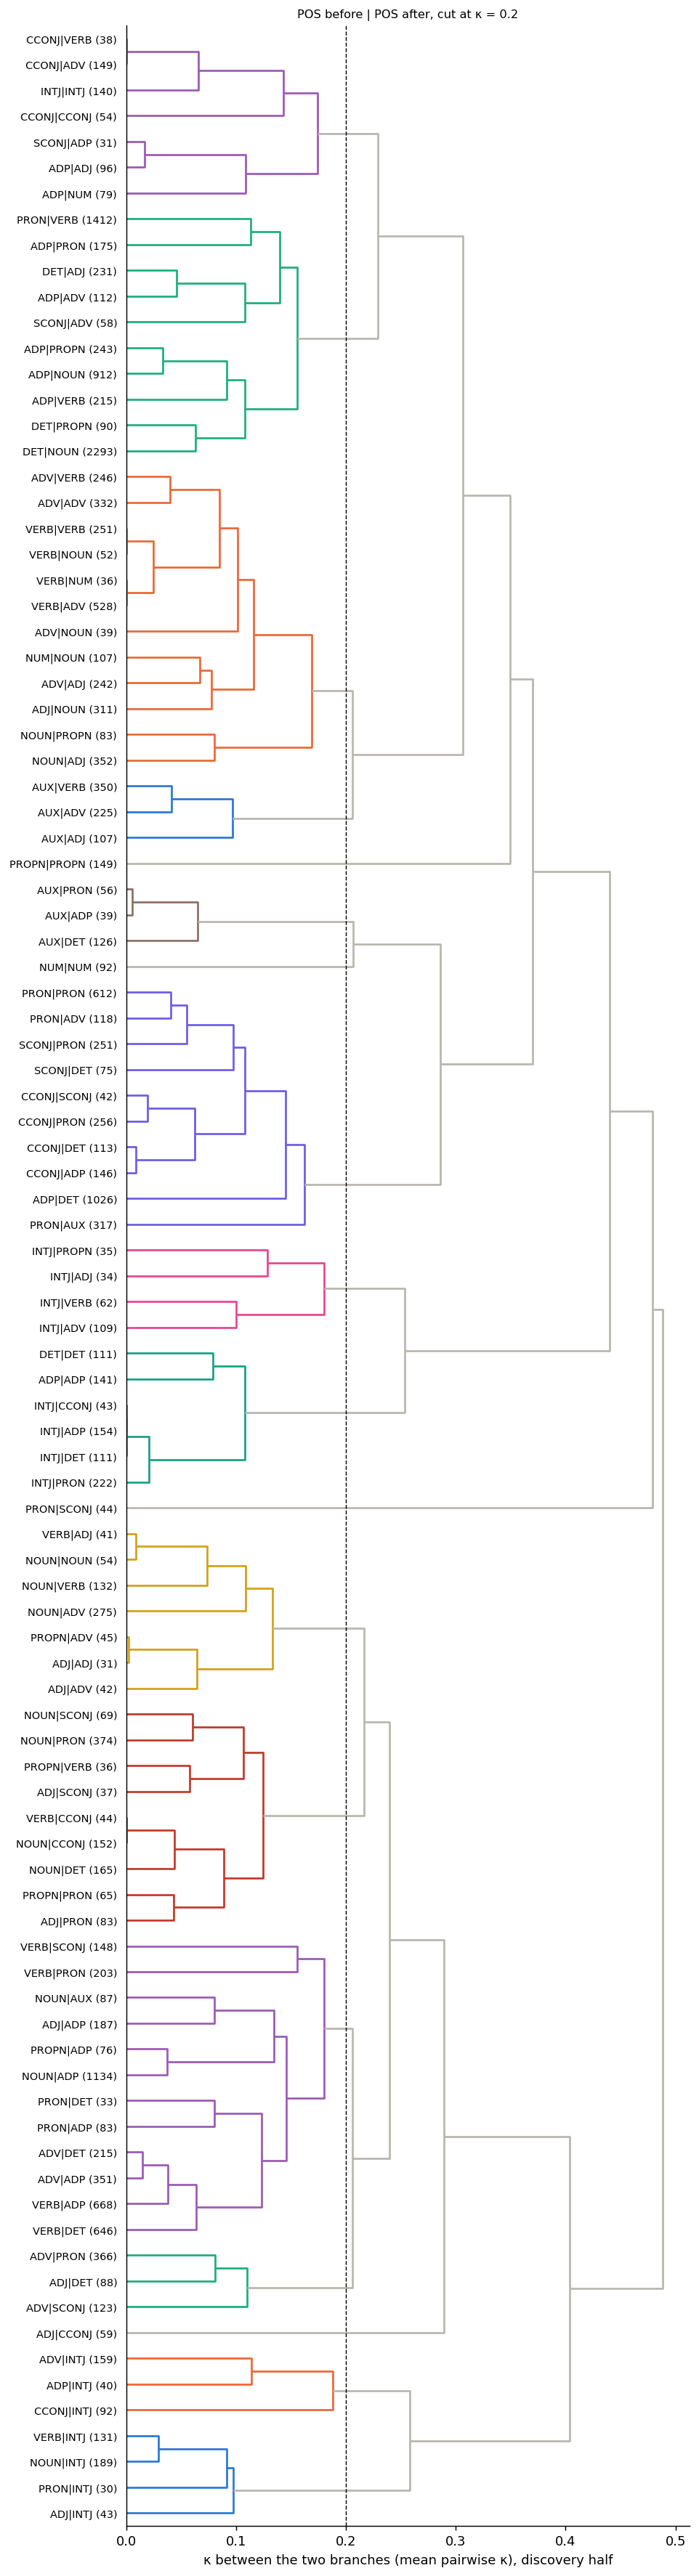

DET|NOUN + PRON|VERB + ADP|NOUN (+7)  (5741 gaps)
    = DET|NOUN, PRON|VERB, ADP|NOUN, ADP|PROPN, DET|ADJ, ADP|VERB, ADP|PRON, ADP|ADV, DET|PROPN, SCONJ|ADV
NOUN|ADP + VERB|ADP + VERB|DET (+9)  (3831 gaps)
    = NOUN|ADP, VERB|ADP, VERB|DET, ADV|ADP, ADV|DET, VERB|PRON, ADJ|ADP, VERB|SCONJ, NOUN|AUX, PRON|ADP, PROPN|ADP, PRON|DET
ADP|DET + PRON|PRON + PRON|AUX (+7)  (2956 gaps)
    = ADP|DET, PRON|PRON, PRON|AUX, CCONJ|PRON, SCONJ|PRON, CCONJ|ADP, PRON|ADV, CCONJ|DET, SCONJ|DET, CCONJ|SCONJ
VERB|ADV + NOUN|ADJ + ADV|ADV (+9)  (2579 gaps)
    = VERB|ADV, NOUN|ADJ, ADV|ADV, ADJ|NOUN, VERB|VERB, ADV|VERB, ADV|ADJ, NUM|NOUN, NOUN|PROPN, VERB|NOUN, ADV|NOUN, VERB|NUM
NOUN|PRON + NOUN|DET + NOUN|CCONJ (+6)  (1025 gaps)
    = NOUN|PRON, NOUN|DET, NOUN|CCONJ, ADJ|PRON, NOUN|SCONJ, PROPN|PRON, VERB|CCONJ, ADJ|SCONJ, PROPN|VERB
INTJ|PRON + INTJ|ADP + ADP|ADP (+3)  (782 gaps)
    = INTJ|PRON, INTJ|ADP, ADP|ADP, DET|DET, INTJ|DET, INTJ|CCONJ
AUX|VERB + AUX|ADV + AUX|ADJ  (682 gaps)
    = AUX|VERB,

In [17]:
# CHOSEN = "relation (governor) × direction"          # any key of LEAF_OPTIONS
# CHOSEN = "relation × direction"                     # any key of LEAF_OPTIONS
# CHOSEN = "family (comp/mod by governor) × direction"  # any key of LEAF_OPTIONS
CHOSEN = "POS before | POS after"                  # any key of LEAF_OPTIONS
D = DISCOVERED[CHOSEN]
plot_tree(D, f"{CHOSEN}, cut at κ = {KAPPA_MIN}")
plt.show()
print_groups(D)


POS before | POS after: 18 groups, 20869 test gaps (95% covered); mean kappa 0.152
                                        gaps  stability  chance  kappa
NOUN|INTJ + VERB|INTJ + ADJ|INTJ (+1)    393      0.326   0.058  0.285
ADV|INTJ + CCONJ|INTJ + ADP|INTJ         291      0.294   0.054  0.253
INTJ|ADV + INTJ|VERB + INTJ|PROPN (+1)   240      0.266   0.052  0.226
PROPN|PROPN                              149      0.259   0.044  0.225
INTJ|PRON + INTJ|ADP + ADP|ADP (+3)      782      0.257   0.063  0.207
PRON|SCONJ                                44      0.212   0.024  0.193
NUM|NUM                                   92      0.187   0.035  0.158
NOUN|PRON + NOUN|DET + NOUN|CCONJ (+6)  1025      0.200   0.065  0.144
ADP|DET + PRON|PRON + PRON|AUX (+7)     2956      0.203   0.069  0.144
DET|NOUN + PRON|VERB + ADP|NOUN (+7)    5741      0.198   0.070  0.138
AUX|VERB + AUX|ADV + AUX|ADJ             682      0.181   0.062  0.126
ADJ|CCONJ                                 59      0.140   0.028  

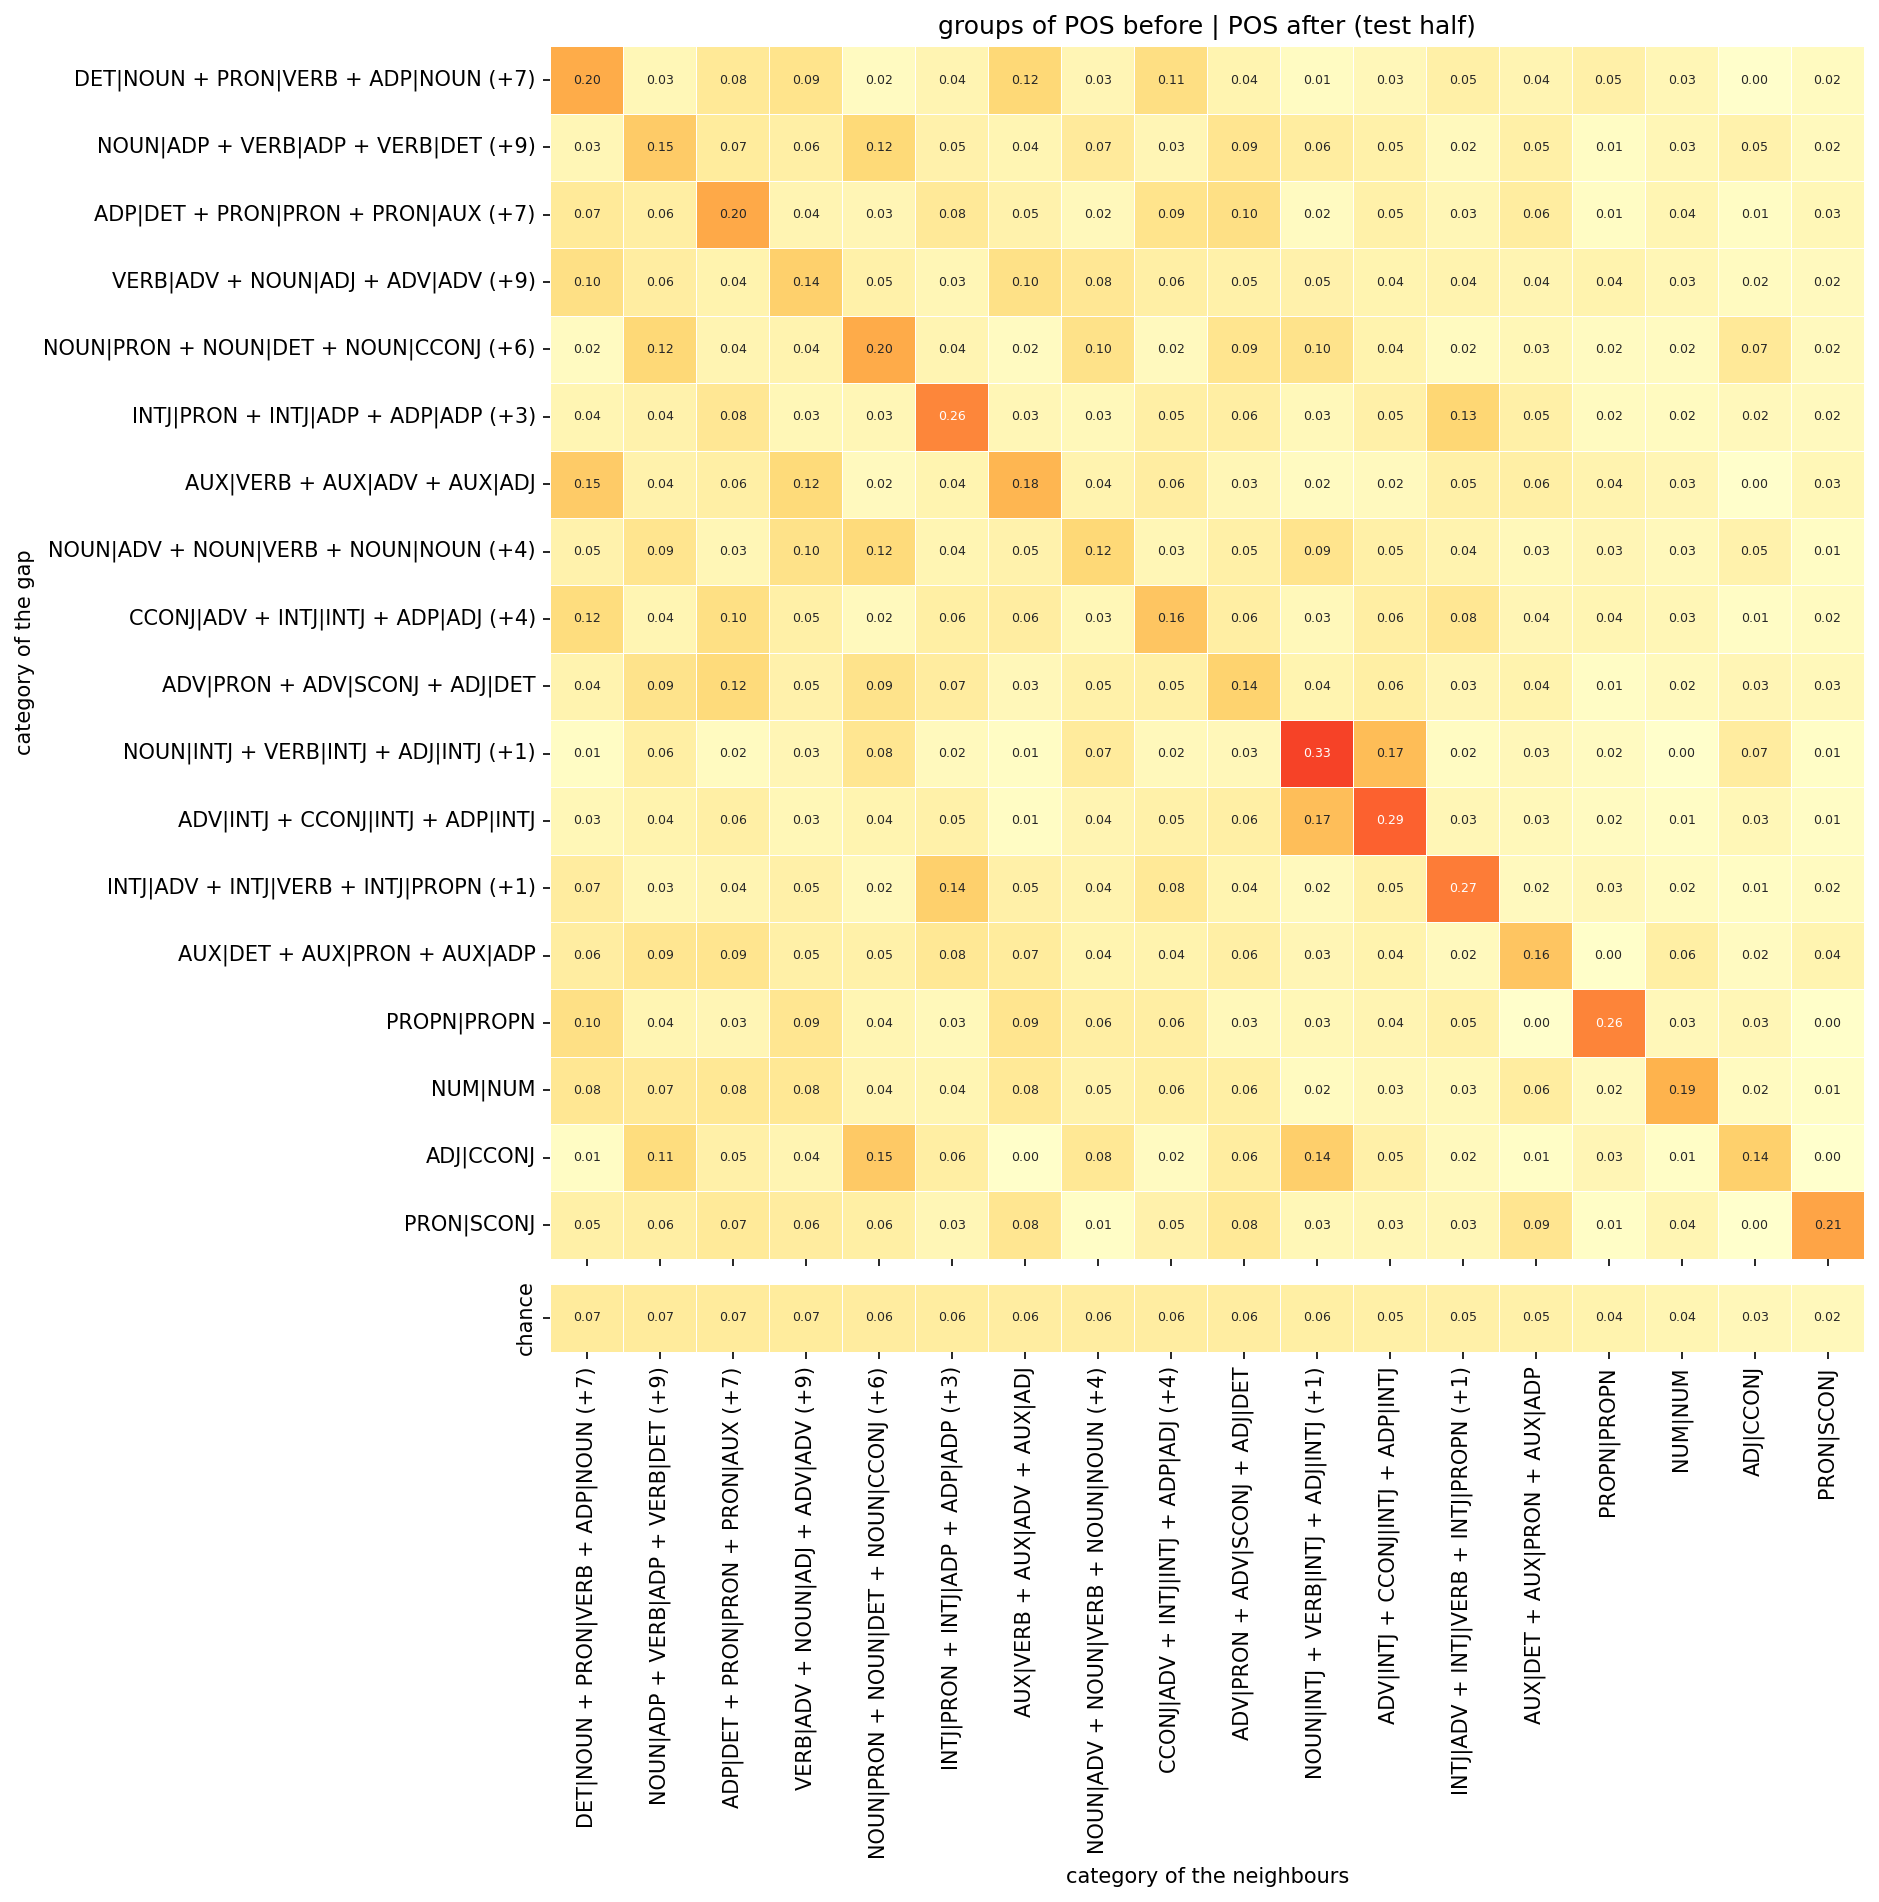

In [18]:
# The groups as a categorisation, on the test half
lab_t = D["grouped"][TEST]
names_t, counts_t = np.unique(lab_t, return_counts=True)
TEST_CATS = [c for c, n in zip(names_t, counts_t) if n >= MIN_CAT and c != "rare"]
keep_t = np.isin(lab_t, TEST_CATS)
TEST_LABELS = np.searchsorted(TEST_CATS, lab_t[keep_t])
NB_T = restrict(NB_TEST, keep_t)
TEST_ROWS = np.where(TEST)[0][keep_t]                     # GAP_M / GAPS_DF rows of the tested gaps
obs_df, ch_df, table, overlaps = full_stability(NB_T, TEST_LABELS, TEST_CATS, N_PERM, np.random.default_rng(SEED))
print(f"{CHOSEN}: {len(TEST_CATS)} groups, {keep_t.sum()} test gaps ({100 * keep_t.mean():.0f}% covered); "
      f"mean kappa {table['kappa'].mean():.3f}")
with pd.option_context("display.width", 250, "display.max_colwidth", 80):
    print(table.sort_values("kappa", ascending=False).round(3).to_string())
    print("\noverlaps:")
    print(overlaps.round(3).to_string())
plot_stability(obs_df, ch_df, table, f"groups of {CHOSEN} (test half)");


## What the groups are made of
This is `gap_partitions` Step 8, on the test half. A group's **profile** is the share of its gaps that carry each feature, measured against the **average group**.
* The first table lists each group's most distinctive features, in percentage points.
* The plot shows the features two groups share (they deviate from the average in the same direction) and those that keep them apart (they deviate in opposite directions).
* **Bridge gaps** are gaps of the first group whose neighbourhood leans towards the second.

Set `C0, C1` to compare any two groups.

ADJ|CCONJ                                 before:AvgHeightGlo=M -37, before:Foot=Begin +36, before:AvgHeightGlo=H +34, before:Prominence=Strong +33, before:Group=Begin +30
ADP|DET + PRON|PRON + PRON|AUX (+7)                               after:Foot=Begin -30, before:Foot=End -29, before:Dur_short +27, before:Dur_long -26, after:Group=End -26
ADV|INTJ + CCONJ|INTJ + ADP|INTJ                           after:Dur_long +46, pair:F0_jump=down +34, before:Package=Begin +34, before:Group=Begin +28, after:Dur_short -25
ADV|PRON + ADV|SCONJ + ADJ|DET                             after:Foot=End -25, after:Group=End -25, after:Package=End -21, before:Group=Begin +18, before:Package=Begin +15
AUX|DET + AUX|PRON + AUX|ADP                                  before:Foot=Begin -39, before:Group=Begin -32, before:Foot=End -28, after:Foot=Begin -28, after:Group=End -26
AUX|VERB + AUX|ADV + AUX|ADJ                            before:Foot=Begin -34, after:Group=End +29, before:Group=Begin -28, after:Package=Be

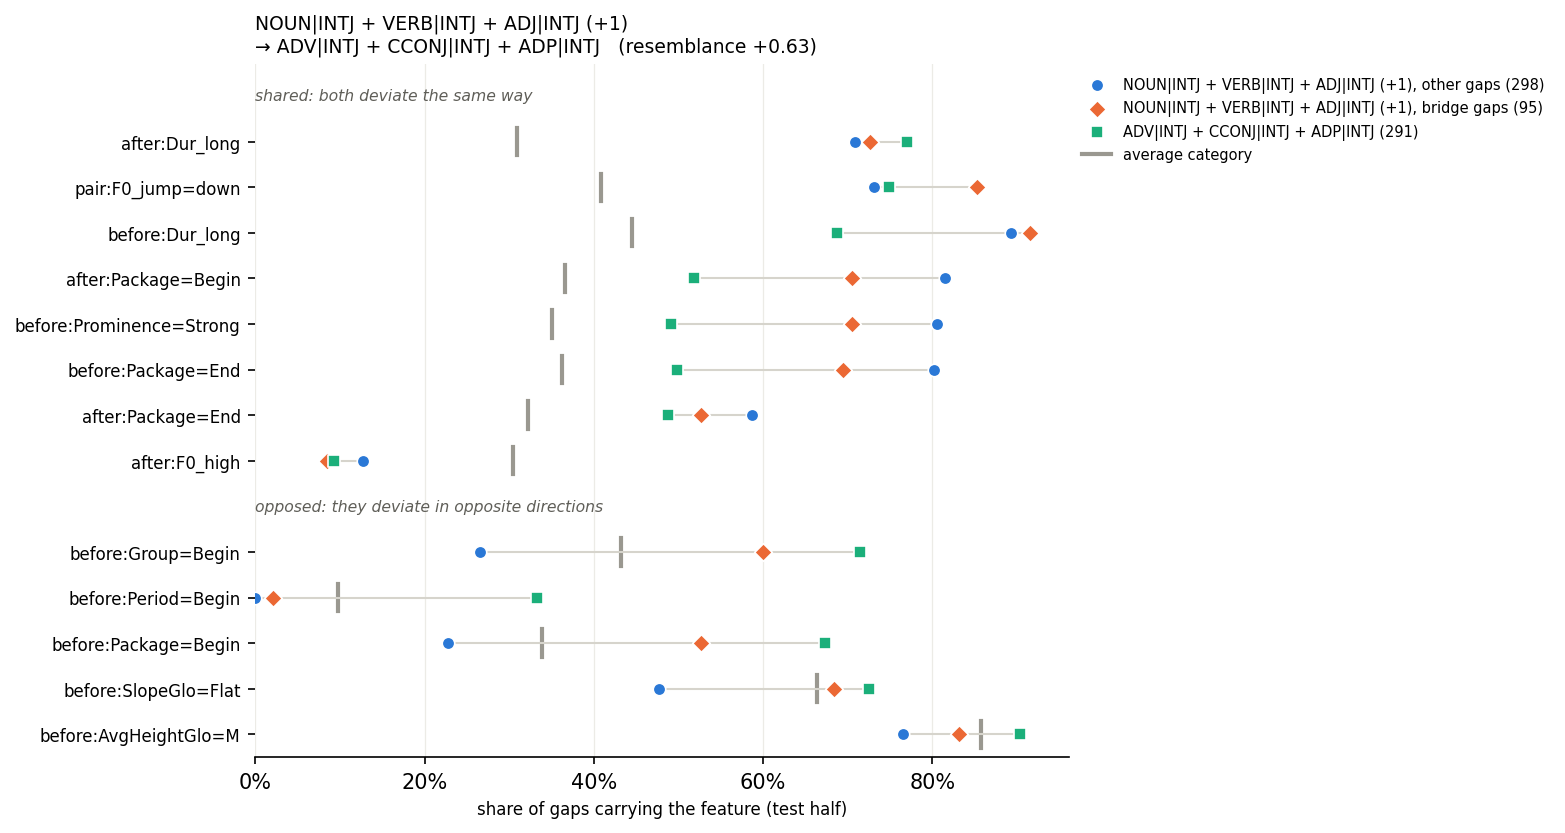

In [19]:
# What pulls two groups together, and what keeps them apart (gap_partitions Step 8, on the test half).
# PROFILE of a group = share of its gaps carrying each feature; REF = the average group (or all gaps).
# Feature f contributes d0(f)·d1(f) / (|d0| |d1|), with d = profile − REF:
#   > 0 shared (both groups deviate the same way), < 0 opposed. The sum is the resemblance (−1 to 1).
FEATS = [idx2feature[j] for j in range(GAP_M.shape[1])]
REFERENCE = "average category"      # or "all gaps"
_, S_T, HAS_T = stability(NB_T, TEST_LABELS, len(TEST_CATS))
PROFILES = np.vstack([GAP_M[TEST_ROWS[TEST_LABELS == c]].mean(0) for c in range(len(TEST_CATS))])
REF = PROFILES.mean(0) if REFERENCE == "average category" else GAP_M[TEST_ROWS].mean(0)


def variable(f):
    """Values that exclude each other form one variable; Begin and End of a unit stay separate."""
    side, rest = f.split(":", 1)
    if rest.endswith(("=Begin", "=End")):
        return f
    return f"{side}:{rest.split('=')[0]}" if "=" in rest else f"{side}:{rest.split('_')[0]}"


def region(f):
    side = f.split(":")[0]
    if side == "pair":
        return "pair"
    return f"{side} / {'acoustic' if any(m in f for m in ('Dur_', 'F0_', 'Glo')) else 'perceptual'}"


REGION = np.array([region(f) for f in FEATS])
REGION_ORDER = ["before / perceptual", "before / acoustic", "pair", "after / acoustic", "after / perceptual"]


def characterise(c, k=8):
    """The k features on which group c departs most from the reference, in percentage points."""
    d = pd.Series(100 * (PROFILES[TEST_CATS.index(c)] - REF), index=FEATS)
    return d.reindex(d.abs().sort_values(ascending=False).index).head(k).round(0)


def bridge_gaps(c0, c1):
    """Gaps of c0 whose neighbourhood holds at least as much c1 as c0 (and some c1)."""
    a, b = TEST_CATS.index(c0), TEST_CATS.index(c1)
    return TEST_ROWS[(TEST_LABELS == a) & HAS_T & (S_T[:, b] > 0) & (S_T[:, b] >= S_T[:, a])]


def shared_table(c0, c1):
    d0, d1 = PROFILES[TEST_CATS.index(c0)] - REF, PROFILES[TEST_CATS.index(c1)] - REF
    return pd.DataFrame({"feature": FEATS, "variable": [variable(f) for f in FEATS], "region": REGION,
                         "reference": REF, c0: PROFILES[TEST_CATS.index(c0)], c1: PROFILES[TEST_CATS.index(c1)],
                         "contrib": d0 * d1 / (np.linalg.norm(d0) * np.linalg.norm(d1))}
                        ).sort_values("contrib", ascending=False)


def region_table(c0, c1):
    g = shared_table(c0, c1).groupby("region")["contrib"]
    out = pd.DataFrame({"shared": g.apply(lambda x: x[x > 0].sum()), "opposed": g.apply(lambda x: x[x < 0].sum()),
                        "net": g.sum()}).reindex(REGION_ORDER)
    out.loc["total"] = out.sum()
    return out


COLOURS = {"typical": "#2a78d6", "bridge": "#eb6834", "rival": "#1baf7a"}
MARKERS = {"typical": "o", "bridge": "D", "rival": "s"}


def plot_overlap(c0, c1, k_shared=8, k_opposed=5):
    t = shared_table(c0, c1)
    t = t.loc[t.groupby("variable")["contrib"].apply(lambda s: s.abs().idxmax())]
    shared, opposed = t[t.contrib > 0].nlargest(k_shared, "contrib"), t[t.contrib < 0].nsmallest(k_opposed, "contrib")
    b_ids = bridge_gaps(c0, c1)
    t_ids = np.setdiff1d(TEST_ROWS[TEST_LABELS == TEST_CATS.index(c0)], b_ids)
    lines = {"typical": GAP_M[t_ids].mean(0), "bridge": GAP_M[b_ids].mean(0) if len(b_ids) else None,
             "rival": PROFILES[TEST_CATS.index(c1)]}
    labels_ = {"typical": f"{c0}, other gaps ({len(t_ids)})", "bridge": f"{c0}, bridge gaps ({len(b_ids)})",
               "rival": f"{c1} ({(TEST_LABELS == TEST_CATS.index(c1)).sum()})"}
    fig, ax = plt.subplots(figsize=(7, 0.32 * (len(shared) + len(opposed) + 2) + 1.2), dpi=150)
    y, yt, yl, first = 0, [], [], True
    for header, block in (("shared: both deviate the same way", shared),
                          ("opposed: they deviate in opposite directions", opposed)):
        if not len(block):
            continue
        ax.annotate(header, (0, y), xycoords=("axes fraction", "data"), fontsize=7.5, color="#5f5e58",
                    style="italic", va="center")
        y += 1
        for _, r in block.iterrows():
            j = FEATS.index(r["feature"])
            ax.plot([REF[j]] * 2, [y - 0.3, y + 0.3], color="#9a9890", lw=2, zorder=1)
            xs = [v[j] for v in lines.values() if v is not None]
            ax.plot([min(xs), max(xs)], [y, y], color="#d6d4cc", lw=1, zorder=1)
            for k, v in lines.items():
                if v is not None:
                    ax.scatter(v[j], y, s=36, color=COLOURS[k], marker=MARKERS[k], edgecolor="white",
                               linewidth=0.8, zorder=3, label=labels_[k] if first else None)
            first = False
            yt.append(y); yl.append(r["feature"])
            y += 1
    ax.plot([], [], color="#9a9890", lw=2, label=REFERENCE)
    ax.set_yticks(yt, yl, fontsize=8)
    ax.set_ylim(y - 0.5, -0.7)
    ax.set_xlim(0, None)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_xlabel("share of gaps carrying the feature (test half)", fontsize=8)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.grid(axis="x", color="#ecebe6", lw=0.6)
    ax.set_axisbelow(True)
    ax.set_title(f"{c0}\n→ {c1}   (resemblance {region_table(c0, c1).loc['total', 'net']:+.2f})", fontsize=9, loc="left")
    ax.legend(fontsize=7, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    return fig


def examples(c, n=5):
    for x in GAPS_DF.loc[TEST_ROWS[TEST_LABELS == TEST_CATS.index(c)], "context"].sample(n, random_state=SEED):
        print("  ·", x)


# Every group against the reference
with pd.option_context("display.width", 250, "display.max_colwidth", 200):
    print(pd.Series({c: ", ".join(f"{f} {v:+.0f}" for f, v in characterise(c, 5).items()) for c in TEST_CATS},
                    name="most distinctive features (pp)").to_string())

# Two groups: by default the largest overlap, else the two largest groups
C0, C1 = overlaps.index[0] if len(overlaps) else tuple(table.sort_values("gaps", ascending=False).index[:2])
print(f"\nresemblance {C0} / {C1}:")
print(region_table(C0, C1).round(3).to_string())
for c in (C0, C1):
    print(f"\n{c}:"); examples(c)
plot_overlap(C0, C1);


## Check: do both halves find the same groups?
Discover again on the test half and compare the two groupings of the starting categories they share. The adjusted Rand index (ARI) is 1 when the groups are the same, and 0 when they are no more alike than chance. Groups that change between halves are the fragile part of the tree. Since the test half is smaller, rare starting categories may be missing from one side.

In [13]:
from sklearn.metrics import adjusted_rand_score
D2 = discover(D["leaves"], half=TEST)
common = sorted(set(D["group_of"]) & set(D2["group_of"]))
ari = adjusted_rand_score([D["group_of"][c] for c in common], [D2["group_of"][c] for c in common])
print(f"{len(common)} starting categories in both halves; ARI = {ari:.2f}")
print("\nGroups found on the test half:")
print_groups(D2)


41 starting categories in both halves; ARI = 0.67

Groups found on the test half:
comp:obj (V) → + mod (V) → + mod (N) → (+10)  (3735 gaps)
    = comp:obj (V) →, mod (V) →, mod (N) →, udep (N) →, mod (V) ←, comp:obl (V) →, dislocated:subj (V) ←, repair (V) →, mod (P) ←, comp:obl (N) →, comp:obl (Adv) →, conj:dicto (V) →, comp:cleft (V) →
comp:obj (P) → + det (N) ←  (3026 gaps)
    = comp:obj (P) →, det (N) ←
subj (V) ← + cc (V) ← + comp:obj (C) → (+3)  (1729 gaps)
    = subj (V) ←, cc (V) ←, comp:obj (C) →, cc (N) ←, cc (P) ←, subj (V) →
comp:aux (V) → + comp:pred (V) → + comp:obj (V) ← (+2)  (806 gaps)
    = comp:aux (V) →, comp:pred (V) →, comp:obj (V) ←, comp (V) ←, comp:obl (V) ←
mod (N) ← + mod (A) ← + mod (Adv) ←  (469 gaps)
    = mod (N) ←, mod (A) ←, mod (Adv) ←
discourse (V) ← + repair (P) → + repair (D) → (+3)  (417 gaps)
    = discourse (V) ←, repair (P) →, repair (D) →, repair (N) →, discourse (N) ←, repair (X) →
conj:coord (N) → + conj:coord (P) → + conj:appos (N) → (+3)  